# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [1]:
ПІБ = 'Цимбалюк Антон Едуардович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-34'      # напр. 'КН-31'
ВАРІАНТ = 15     # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [2]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Цимбалюк Антон Едуардович, ШІ-34, варіант 15
ваш потік:                   E>0.8
ваша пара для графіка 3:     потік E>0.8 та потік P>10
ваш агрегат для етапу 4:     середнє
ваше додаткове питання:      Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [4]:
# ВАШ КОД
pd.read_excel("20171129_FINAL_FINAL.xlsx")

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7220,NaN,2017,9,21,2335,58017,84900,21.9,0.361,0.202,0.084,0.0717,0.0475,143000,32900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7221,NaN,2017,9,21,2340,58017,85200,14.1,0.343,0.309,0.118,0.0679,0.0328,143000,32100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7222,NaN,2017,9,21,2345,58017,85500,27.1,0.465,0.237,0.106,0.0593,0.0251,140000,32500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7223,NaN,2017,9,21,2350,58017,85800,23.7,0.36,0.205,0.127,0.091,0.0363,140000,32700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Відповідь 1.1:**  
read_excel() функція бере за замовчуванням перший рядок і використовує данні в ньому як назви для колонок, а так як вони пусті то ми отримуємо unnamed. Так як перші 25 рядків складаються з метаданних та пустих рядків тому ми маємо такий вигляд перших рядків через pandas.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [5]:
# ВАШ КОД
RAW = pd.read_excel("20171129_FINAL_FINAL.xlsx", header=None)
RAW.head(30)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [6]:
RAW.notna().sum()

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64

**Відповідь 1.3:**  
За непусти стовпями бачимо 3 згустки, які є нашими таблицями.  
Перша таблиця складається з стовпчиків з 1 по 14, друга таблиця з 16 по 19 та третя таблиця з 24 по 31

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [7]:

print('--- Table A (columns B–O) ---')
display(RAW.iloc[:26, 1:15].dropna(how='all'))

print('--- Table B (columns Q–T) ---')
display(RAW.iloc[:27, 16:20].dropna(how='all'))

print('--- Table C (columns Y–AF) ---')
display(RAW.iloc[:27, 24:32].dropna(how='all'))

--- Table A (columns B–O) ---


,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,# Label: P >30 = Particles at >30 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


--- Table B (columns Q–T) ---


,16,17,18,19
13,ftp://ftp.swpc.noaa.gov/pub/indices/old_indice...,NaN,NaN,NaN
15,Product: Daily Solar Data quar_DSD.txt,NaN,NaN,NaN
16,:Issued: 0825 UT 04 Oct 2017,NaN,NaN,NaN
17,#,NaN,NaN,NaN
18,"# Prepared by the U.S. Dept. of Commerce, NOA...",NaN,NaN,NaN
19,# Please send comments and suggestions to SWP...,NaN,NaN,NaN
23,Quarterly Daily Solar Data,NaN,NaN,NaN
26,NaN,Month,Date,Radio Flux 10.7


--- Table C (columns Y–AF) ---


,24,25,26,27,28,29,30,31
0,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
26,NaN,NaN,# YR,MO,DA,HH,SPEED,DENSITY


**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | NOAA Space Weather Prediction Center; супутник GOES-15 | Протони: protons/(cm²·s·sr); електрони: electrons/(cm²·s·sr) |
| B | NOAA Space Weather Prediction Center, файл Quarterly Daily Solar Data | Радіопотік F10.7: solar flux units (sfu), 10⁻²² W/(m²·Hz) |
| C | SOHO CELIAS Proton Monitor (UMD) | Швидкість протонів — km/s; густина протонів — protons/cm³ |


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [8]:
A = RAW.iloc[26:7226, 1:15].copy()
A.columns = ['year', 'month', 'day', 'time_hhmm', 'modified_julian_day',
             'seconds_of_day', 'P>1', 'P>5', 'P>10', 'P>30', 'P>50',
             'P>100', 'E>0.8', 'E>2.0']

B = RAW.iloc[27:52, 16:20].copy()
B.columns = ['year', 'month', 'day', 'radio_flux_f107']

C = RAW.iloc[27:628, 24:32].copy()
C.columns = ['hour_counter_1', 'hour_counter_2', 'year', 'month', 'day',
             'hour', 'solar_wind_speed', 'solar_wind_density']

for table in (A, B, C):
    for column in table.columns:
        table[column] = pd.to_numeric(table[column], errors='coerce')

print('A:', A.shape)
display(A.head())
print('B:', B.shape)
display(B.head())
print('C:', C.shape)
display(C.head())

A: (7200, 14)


,year,month,day,time_hhmm,modified_julian_day,seconds_of_day,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2.0
26,2017,8,28,0,57993,0,12.00,0.260,0.180,0.1140,0.1040,0.0793,23600.0,1180.0
27,2017,8,28,5,57993,300,19.40,0.690,0.314,0.1120,0.0612,0.0251,23100.0,1160.0
28,2017,8,28,10,57993,600,8.48,0.168,0.130,0.0717,0.0614,0.0304,22200.0,1090.0
29,2017,8,28,15,57993,900,15.40,0.566,0.198,0.0926,0.0568,0.0251,20400.0,997.0
30,2017,8,28,20,57993,1200,6.41,0.156,0.118,0.0597,0.0494,0.0251,18500.0,875.0


B: (25, 4)


,year,month,day,radio_flux_f107
27,2017,8,28,82
28,2017,8,29,84
29,2017,8,30,87
30,2017,8,31,92
31,2017,9,1,93


C: (601, 8)


,hour_counter_1,hour_counter_2,year,month,day,hour,solar_wind_speed,solar_wind_density
27,0.0,0.0,17,8,28,0,285,3.0
28,1.0,1.0,17,8,28,1,305,3.4
29,2.0,2.0,17,8,28,2,309,1.7
30,3.0,3.0,17,8,28,3,304,2.0
31,4.0,4.0,17,8,28,4,302,2.3


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [9]:

A['ts'] = (
    pd.to_datetime(A[['year', 'month', 'day']])
    + pd.to_timedelta(A['time_hhmm'] // 100, unit='h')
    + pd.to_timedelta(A['time_hhmm'] % 100, unit='min')
)

B['ts'] = pd.to_datetime(B[['year', 'month', 'day']])


C['ts'] = pd.to_datetime({
    'year': C['year'] + 2000,       #рік записано як 17 тому додаєм 2000
    'month': C['month'],
    'day': C['day'],
    'hour': C['hour']
})

for name, table in [('A', A), ('B', B), ('C', C)]:
    print(name, ':', table['ts'].min(), '—', table['ts'].max())

A : 2017-08-28 00:00:00 — 2017-09-21 23:55:00
B : 2017-08-28 00:00:00 — 2017-09-21 00:00:00
C : 2017-08-28 00:00:00 — 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [10]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [11]:
print(f"Description for A table: \n{A.describe()}")
print(f"\nDescription for B table: \n{B.describe()}")
print(f"\nDescription for C table: \n{C.describe()}")



Description for A table: 
         year        month          day    time_hhmm  modified_julian_day  seconds_of_day           P>1          P>5         P>10         P>30         P>50       P>100          E>0.8          E>2.0  \
count  7200.0  7200.000000  7200.000000  7200.000000          7200.000000     7200.000000   7197.000000  7197.000000  7197.000000  7197.000000  7197.000000  7197.00000    7197.000000    7197.000000   
mean   2017.0     8.840000    13.960000  1177.500000         58005.000000    43050.000000    689.325064   156.626057    76.474020    18.838604     7.446840     1.65929   81862.741801   11401.502123   
min    2017.0     8.000000     1.000000     0.000000         57993.000000        0.000000      0.429000     0.151000     0.117000     0.057600     0.045500     0.02240       4.300000       0.133000   
25%    2017.0     9.000000     7.000000   588.750000         57999.000000    21525.000000     11.700000     0.279000     0.186000     0.098400     0.059700     0.02630   

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [12]:
columns_to_check = ['solar_wind_speed', 'solar_wind_density']

before = C[columns_to_check].agg(['mean', 'min'])
negative_counts = (C[columns_to_check] < 0).sum()

print('Negative values:')
display(negative_counts)
print('Statistics before sreplacement:')
display(before)

for column in columns_to_check:
    C[column] = C[column].where(C[column] >= 0, np.nan)

after = C[columns_to_check].agg(['mean', 'min'])
print('Statistics after replacement with NaN:')
display(after)

Negative values:


solar_wind_speed      8
solar_wind_density    8
dtype: int64

Statistics before sreplacement:


,solar_wind_speed,solar_wind_density
mean,506.547421,2.907654
min,-1.000000,-1.000000


Statistics after replacement with NaN:


,solar_wind_speed,solar_wind_density
mean,513.394604,2.960371
min,277.000000,0.100000


**Відповідь 3.2:**  
Значення `-1` — це позначка пропущених даних у службовому описі, а не фізичні вимірювання. У стовпцях швидкості та густини є по 8 таких значень. До заміни середня швидкість дорівнювала 506.55 km/s, а мінімум — −1 km/s; після заміни — 513.39 km/s і 277 km/s. Для густини середнє змінилося з 2.91 до 2.96, а мінімум — з −1 до 0.1 . Отже, значення `-1` штучно занижували середні та давали фізично неможливий мінімум.

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [13]:
A.describe()

,year,month,day,time_hhmm,modified_julian_day,seconds_of_day,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2.0,ts
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.00000,7197.000000,7197.000000,7200
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000,689.325064,156.626057,76.474020,18.838604,7.446840,1.65929,81862.741801,11401.502123,2017-09-09 11:57:30
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000,0.429000,0.151000,0.117000,0.057600,0.045500,0.02240,4.300000,0.133000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000,11.700000,0.279000,0.186000,0.098400,0.059700,0.02630,22200.000000,552.000000,2017-09-03 05:58:45
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000,55.400000,0.632000,0.376000,0.146000,0.086600,0.03630,68600.000000,4290.000000,2017-09-09 11:57:30
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000,560.000000,107.000000,35.800000,0.990000,0.249000,0.06700,143000.000000,14100.000000,2017-09-15 17:56:15
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000,32500.000000,2890.000000,1330.000000,399.000000,191.000000,61.50000,259000.000000,110000.000000,2017-09-21 23:55:00
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498,1625.968447,390.921861,222.362627,67.265595,28.620524,7.15889,65728.005824,16920.617446,NaN


**Відповідь 3.3:**  
Стовпці year, month, day, time_hhmm, modified_julian_day і seconds_of_day — це дата, час або службові координати, а не вимірювання. Для них середнє не описує стан космічної погоди. Особливо це видно для time_hhmm: середнє між 1230 і 1330 дорівнює 1280, але часу 12:80 не існує.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [14]:
particle_columns = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

A_hourly = A.set_index('ts')[particle_columns].resample('h').agg(['mean', 'max'])
A_hourly.columns = [f'{column}_{statistic}' for column, statistic in A_hourly.columns]
A_hourly = A_hourly.reset_index()

print(A_hourly.shape)
display(A_hourly.head())

(600, 17)


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

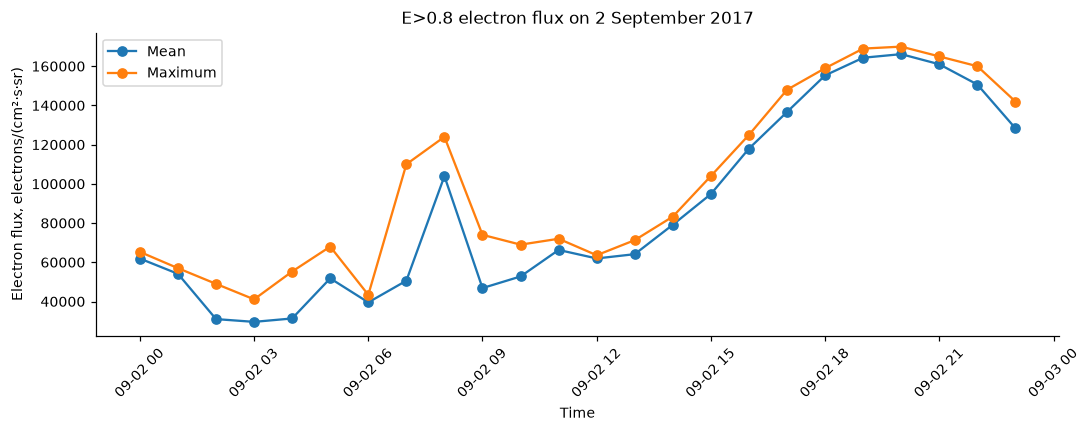

In [15]:
selected_date = pd.Timestamp('2017-09-02')
day_data = A[A['ts'].dt.normalize() == selected_date].set_index('ts')
hourly_comparison = day_data['E>0.8'].resample('h').agg(['mean', 'max'])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hourly_comparison.index, hourly_comparison['mean'], label='Mean', marker='o')
ax.plot(hourly_comparison.index, hourly_comparison['max'], label='Maximum', marker='o')
ax.set_title('E>0.8 electron flux on 2 September 2017')
ax.set_xlabel('Time')
ax.set_ylabel('Electron flux, electrons/(cm²·s·sr)')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

**Відповідь 4.2:** Максимум за годину завжди не менший за середнє і сильніше показує короткі піки за 5-хвилинними вимірюваннями. Різниця суттєва під час різких коротких сплесків потоку: середнє їх згладжує, а максимум зберігає найбільше значення.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [16]:
hourly_index = pd.DataFrame({
    'ts': pd.date_range(B['ts'].min(), B['ts'].max() + pd.Timedelta(days=1) - pd.Timedelta(hours=1), freq='h')
})
daily_flux = B.set_index('ts')['radio_flux_f107']
hourly_index['radio_flux_f107'] = hourly_index['ts'].dt.normalize().map(daily_flux)

inner_M = A_hourly.merge(C, on='ts', how='inner').merge(hourly_index, on='ts', how='inner')
outer_M = A_hourly.merge(C, on='ts', how='outer').merge(hourly_index, on='ts', how='outer')

# Keep the final solar-wind observation even though the other sources end earlier.
M = outer_M.sort_values('ts').reset_index(drop=True)

print('Inner join:', inner_M.shape)
print('Outer join:', outer_M.shape)
print('Rows with at least one missing value:')
display(M[M.isna().any(axis=1)])

Inner join: (600, 26)
Outer join: (601, 26)
Rows with at least one missing value:


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max,hour_counter_1,hour_counter_2,year,month,day,hour,solar_wind_speed,solar_wind_density,radio_flux_f107
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.134,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,7.0,7.0,17,9,4,7,NaN,NaN,140.0
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.134,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,8.0,8.0,17,9,4,8,NaN,NaN,140.0
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.134,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,9.0,9.0,17,9,4,9,NaN,NaN,140.0
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.120,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,10.0,10.0,17,9,4,10,NaN,NaN,140.0
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.110,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,11.0,11.0,17,9,4,11,NaN,NaN,140.0
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.144,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,12.0,12.0,17,9,4,12,NaN,NaN,140.0
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.159,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,13.0,13.0,17,9,4,13,NaN,NaN,140.0
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.166,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,14.0,14.0,17,9,4,14,NaN,NaN,140.0
600,2017-09-22 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,17,9,22,0,381.0,1.0,NaN


**Відповідь 4.3:** `inner` дає 600 рядків, а `outer` — 601. Обрано `outer`, щоб не втратити останнє спостереження сонячного вітру за 22 вересня; для нього немає значень з A і B, тому вони залишилися пропусками.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [17]:
group_order = ['тиха', 'активна', 'дуже активна']
M['група'] = pd.cut(
    M['P>10_max'],
    bins=[-np.inf, 10, 1000, np.inf],
    labels=group_order,
    right=False
)

print(M['група'].value_counts().reindex(group_order))

група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64


**Самоперевірка етапу 4.**

In [18]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 601 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

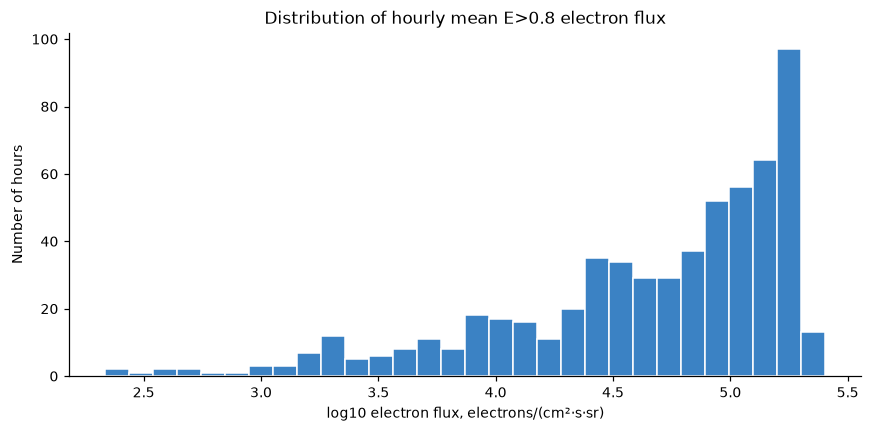

Mean: 81842.47
Median: 69712.50


In [19]:
hourly_flux = M['E>0.8_mean'].dropna()
mean_flux = hourly_flux.mean()
median_flux = hourly_flux.median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(hourly_flux), bins=30, color='#3b82c4', edgecolor='white')
ax.set_title('Distribution of hourly mean E>0.8 electron flux')
ax.set_xlabel('log10 electron flux, electrons/(cm²·s·sr)')
ax.set_ylabel('Number of hours')
plt.tight_layout()
plt.show()

print(f'Mean: {mean_flux:.2f}')
print(f'Median: {median_flux:.2f}')

**Висновок:** E>0.8 має дуже широкий діапазон: 1% годин мають потік до 475, медіана дорівнює 69712.5, а 95% квантиль — 192291.7 electrons/(cm²·s·sr). Верхній хвіст зміщує середнє до 81842.5, тому на звичайній гістограмі малі значення були б майже непомітні; логарифм дозволяє побачити весь діапазон.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

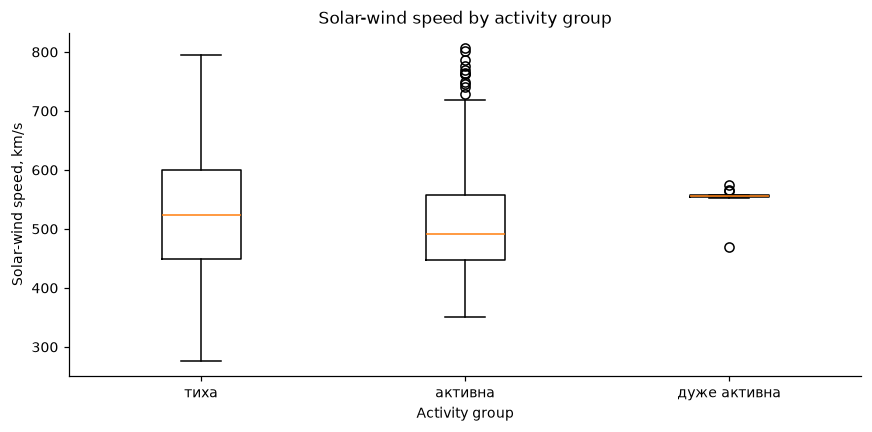

In [20]:
group_order = ['тиха', 'активна', 'дуже активна']
speed_by_group = [
    M.loc[M['група'] == group, 'solar_wind_speed'].dropna()
    for group in group_order
]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(speed_by_group, tick_labels=group_order)
ax.set_title('Solar-wind speed by activity group')
ax.set_xlabel('Activity group')
ax.set_ylabel('Solar-wind speed, km/s')
plt.tight_layout()
plt.show()

**Висновок:** Розподіли швидкості тихих і активних годин перекриваються (медіани 524 і 492 km/s), тому чіткого зв’язку не видно. «Дуже активна» група визначена за P>10, а не за швидкістю вітру: її 18 годин припали майже на одну подію 10–11 вересня, коли 15 із 18 швидкостей були в межах 554–558 km/s. Тому вузька коробка показує сталі умови під час цієї конкретної події, а не правило, що сильний P>10 завжди відповідає швидкості близько 556 km/s.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

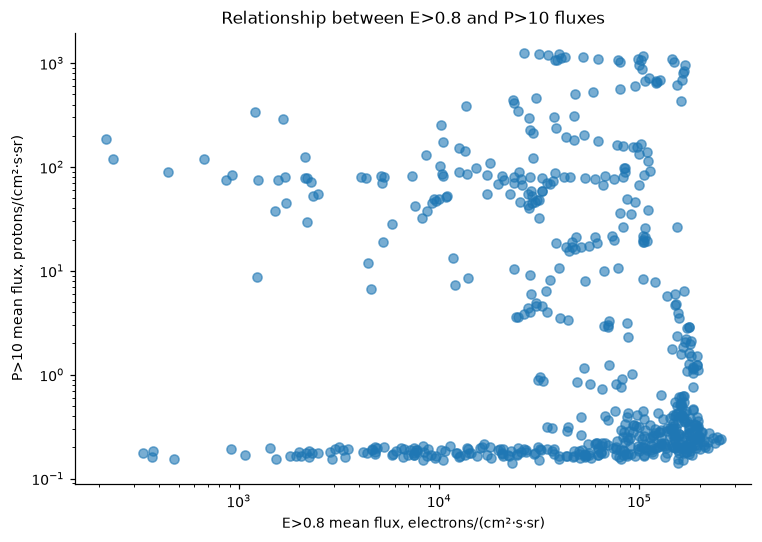

Pearson correlation: -0.049


In [21]:
scatter_data = M[['E>0.8_mean', 'P>10_mean']].dropna()
correlation = scatter_data['E>0.8_mean'].corr(scatter_data['P>10_mean'])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(scatter_data['E>0.8_mean'], scatter_data['P>10_mean'], alpha=0.6)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Relationship between E>0.8 and P>10 fluxes')
ax.set_xlabel('E>0.8 mean flux, electrons/(cm²·s·sr)')
ax.set_ylabel('P>10 mean flux, protons/(cm²·s·sr)')
plt.tight_layout()
plt.show()

print(f'Pearson correlation: {correlation:.3f}')

**Висновок:** Кореляція між погодинними середніми E>0.8 і P>10 дорівнює −0.049, тобто лінійного зв’язку практично немає. Це видно й за піками: найбільший P>10 (1330) був 11 вересня, коли E>0.8 становив 26417, а найбільший E>0.8 (253917) був 19 вересня при P>10 лише 0.437.

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

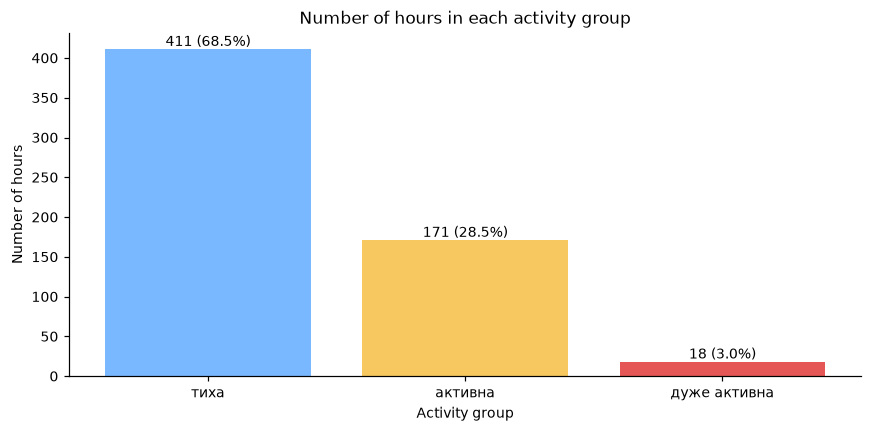

In [22]:
group_order = ['тиха', 'активна', 'дуже активна']
group_counts = M['група'].value_counts().reindex(group_order, fill_value=0)
total_grouped_hours = group_counts.sum()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(group_counts.index, group_counts.values, color=['#79b8ff', '#f6c85f', '#e45756'])
ax.set_title('Number of hours in each activity group')
ax.set_xlabel('Activity group')
ax.set_ylabel('Number of hours')

for bar, count in zip(bars, group_counts.values):
    percentage = count / total_grouped_hours * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{count} ({percentage:.1f}%)', ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Висновок:** Із 600 годин із наявним P>10 411 (68.5%) є тихими, 171 (28.5%) — активними і лише 18 (3.0%) — дуже активними. Ще одна година в M не потрапила на діаграму: це 22 вересня 00:00, коли є дані сонячного вітру, але немає P>10 через різну тривалість джерел.

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

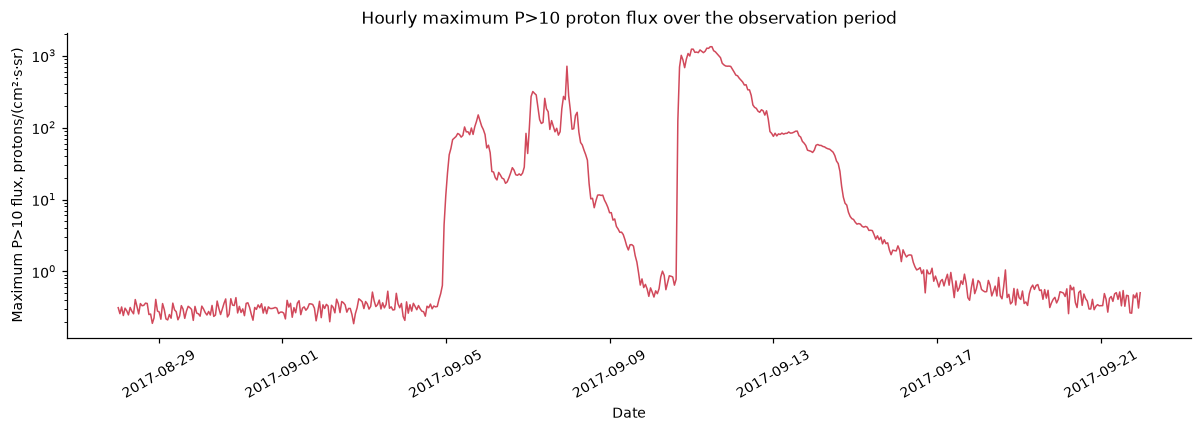

In [23]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(M['ts'], M['P>10_max'], color='#d1495b', linewidth=1)
ax.set_yscale('log')
ax.set_title('Hourly maximum P>10 proton flux over the observation period')
ax.set_xlabel('Date')
ax.set_ylabel('Maximum P>10 flux, protons/(cm²·s·sr)')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Висновок:** Більшу частину періоду P>10 був низьким (медіана максимумів за годину — 0.643 protons/(cm²·s·sr)), але 10–11 вересня стався короткий сильний сплеск: 18 годин перевищили 1000, а піки 1330 зафіксовано 11 вересня о 11:00 та 12:00. Це пояснює, чому лінійна шкала приховала б звичайний фоновий рівень.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

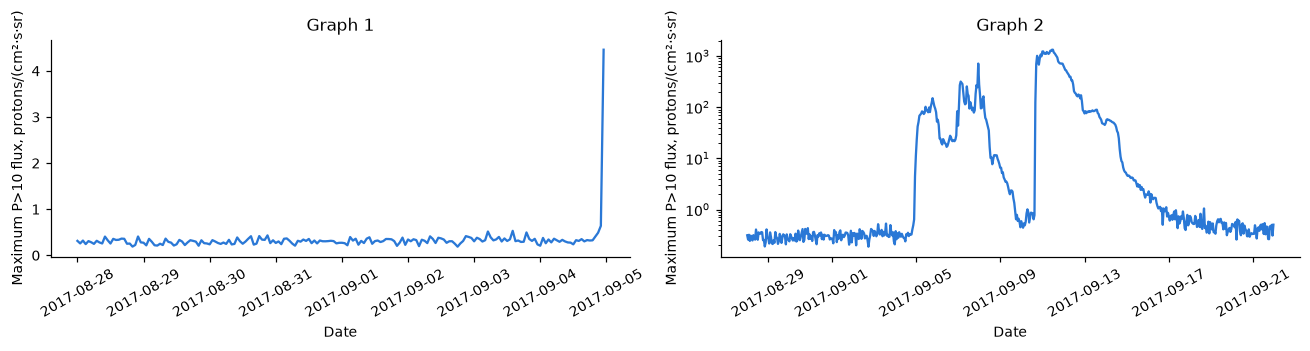

In [24]:
column_name = 'P>10_max'

window_data = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(window_data['ts'], window_data[column_name], color='#2a78d6')
ax[0].set_title('Graph 1')
ax[0].set_xlabel('Date')
ax[0].set_ylabel('Maximum P>10 flux, protons/(cm²·s·sr)')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[column_name], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Graph 2')
ax[1].set_xlabel('Date')
ax[1].set_ylabel('Maximum P>10 flux, protons/(cm²·s·sr)')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: наприкінці серпня — на початку вересня P>10 був низьким, але через лінійну вісь Y короткий підйом до 4.46 виглядає різким стрибком, а звичайні значення близько 0.2–0.6 зливаються. Якщо бачити лише цей графік, можна помилково вирішити, що весь період був спокійним і що цей стрибок був значним.
2. Висновок з другого графіка: на тлі низького фонового потоку 10–11 вересня стався короткий сильний сплеск, коли P>10 перевищував 1000. Логарифмічна вісь дозволяє одночасно побачити фонові значення, малий ранній підйом і справжній масштаб цього сплеску.
3. Дві відмінності між ними: перший графік показує лише 28 серпня — 4 вересня, а другий — весь період; у першого лінійна вісь Y, у другого — логарифмічна.


### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

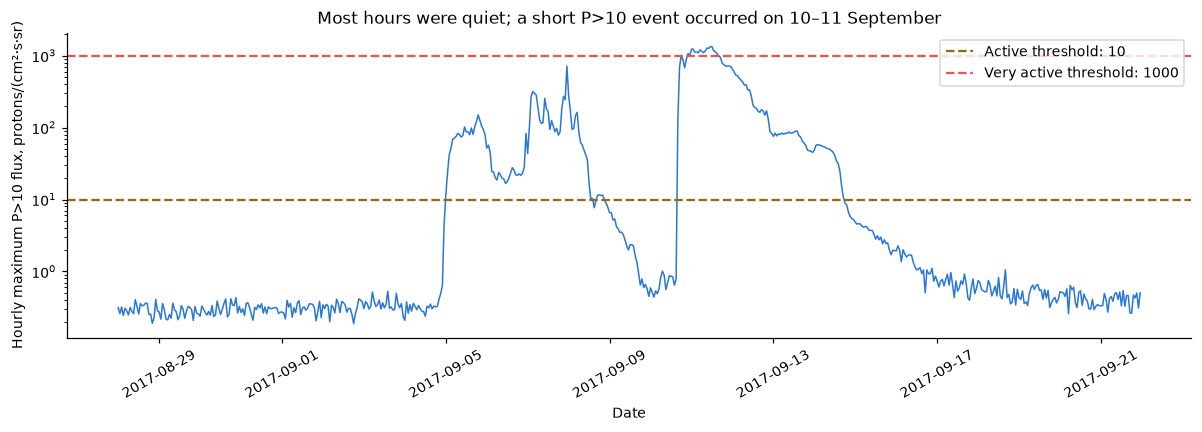

In [25]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(M['ts'], M['P>10_max'], color='#2a78d6', linewidth=1)
ax.set_yscale('log')
ax.axhline(10, color="#906c18", linestyle='--', label='Active threshold: 10')
ax.axhline(1000, color='#e45756', linestyle='--', label='Very active threshold: 1000')
ax.set_title('Most hours were quiet; a short P>10 event occurred on 10–11 September')
ax.set_xlabel('Date')
ax.set_ylabel('Hourly maximum P>10 flux, protons/(cm²·s·sr)')
ax.tick_params(axis='x', rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

**Відповідь 6.2:** Обрано весь період і логарифмічну вісь Y, бо потік змінюється від часток одиниці до понад 1000. Логарифмічна шкала не приховує фонові значення, а горизонтальні лінії порогів одразу показують межі тихої, активної та дуже активної груп.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:** Максимум P>10 за годину досяг 1330 protons/(cm²·s·sr), що приблизно у 2070 разів більше за медіану 0.643; усі 18 дуже активних годин припали на короткий сплеск 10–11 вересня. Це видно в графіках 4 і 5.

**Спостереження 2:** Найбільший E>0.8 (253917 electrons/(cm²·s·sr)) зафіксовано 19 вересня, але тоді P>10 був лише 0.437 protons/(cm²·s·sr). Отже піки потоків різних частинок не збігаються, що також пояснює кореляцію −0.049 у графіку 3.

**Спостереження 3:** У даних сонячного вітру є вісім послідовних годин пропусків — 4 вересня з 07:00 до 14:00. Вони виникли через службове значення −1, яке було замінено на NaN у завданні 3.2, і їх видно серед рядків із пропусками в завданні 4.3.


### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [26]:
hourly_flux = M['E>0.8_mean'].dropna()
median_flux = hourly_flux.median()
hours_above_median = (hourly_flux > median_flux).sum()
share_above_median = hours_above_median / len(hourly_flux) * 100

print(f'Median E>0.8: {median_flux:.2f} electrons/(cm²·s·sr)')
print(f'Hours above the median: {hours_above_median} of {len(hourly_flux)} ({share_above_median:.1f}%)')

Median E>0.8: 69712.50 electrons/(cm²·s·sr)
Hours above the median: 300 of 600 (50.0%)


**Відповідь 7.2:** Погодинне середнє E>0.8 перевищувало власну медіану 69712.50 electrons/(cm²·s·sr) у 300 із 600 годин, тобто у 50.0% спостережень. Це очікувано для медіани: вона ділить впорядковані значення приблизно навпіл; у цьому наборі жодне значення точно їй не дорівнює.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [27]:
ІНСТРУМЕНТИ_ШІ = 'OpenAI Codex'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'код, перевірено',
    'етап 3, паспорт даних і дивні значення':     'код, перевірено',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'текст, перероблено',
    'етапи 6–7, порівняння графіків і спостереження': 'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = ('Перевірено розміри A, B і C: 7200, 25 і 601 рядок. Звірено межі дат у 2017 році, '
                 'кількість груп 411, 171 і 18, кореляцію −0.049 та 300 годин E>0.8 вище медіани. '
                 'Також виправлено заміну −1 на NaN у числових стовпцях, бо присвоєння NaN у int64 давало помилку.')

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True  # Змініть на True лише після того, як зможете пояснити весь код.

In [28]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Цимбалюк Антон Едуардович
інструменти:                                   OpenAI Codex
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    код, перевірено
етап 3, паспорт даних і дивні значення:        код, перевірено
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                текст, перероблено
етапи 6–7, порівняння графіків і спостереження: код, перевірено
------------------------------------------------------------------------------
перевірено автором:
Перевірено розміри A, B і C: 7200, 25 і 601 рядок. Звірено межі дат у 2017 році, кількість груп 411, 171 і 18, кореляцію −0.049 та 300 годин E>0.8 вище медіани. Також виправлено заміну −1 на NaN у числових стовпцях, бо присвоєння NaN у int64 давало помилку.
Автор

---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [29]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (601, 27)


In [30]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
